<a href="https://colab.research.google.com/github/nakitava/image_processing/blob/main/%D0%9F%D1%80%D0%BE%D0%B5%D0%BA%D1%82%D0%BD%D0%B0%D1%8F_%D1%80%D0%B0%D0%B1%D0%BE%D1%82%D0%B0_%E2%84%961_%D0%9A%D0%BB%D0%B0%D1%81%D1%81%D0%B8%D1%84%D0%B8%D0%BA%D0%B0%D1%86%D0%B8%D1%8F_%D0%BE%D0%B1%D1%8A%D0%B5%D0%BA%D1%82%D0%BE%D0%B2_%D0%BD%D0%B0_%D0%B8%D0%B7%D0%BE%D0%B1%D1%80%D0%B0%D0%B6%D0%B5%D0%BD%D0%B8%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## **Проектная работа №1: Классификация объектов на изображении**









### **Цель:**


Разработать программу на Python, которая принимает на вход фотографию с изображением монет и вычисляет общую сумму денежных средств, отображенных на ней, используя только библиотеку OpenCV и стандартные библиотеки Python.


### **Базовая реализация:**



1. **Сбор изображения:**
   - Используйте камеру или загрузите готовое изображение с монетами для обработки.

2. **Предварительная обработка изображения:**
   - Преобразуйте изображение в оттенки серого.
   - Примените размытие Гаусса для уменьшения шума.
   - Используйте оператор Кэнни для обнаружения краев.

3. **Обнаружение кругов (монет):**
   - Используйте преобразование Хафа для обнаружения кругов на изображении.
   - Получите координаты центров и радиусов обнаруженных кругов (монет).

4. **Классификация монет:**
   - Определите номинал каждой монеты на основе ее радиуса.
   - Установите пороговые значения для радиусов, соответствующие разным номиналам:
     - **Маленький радиус:** 1 рубль.
     - **Средний радиус:** 2 рубля.
     - **Большой радиус:** 5 рублей.

5. **Подсчет общей суммы:**
   - Суммируйте номиналы всех обнаруженных монет.
   - Отобразите общую сумму на изображении или в консоли.

6. **Отображение результатов:**
   - Нарисуйте окружности на изображении вокруг обнаруженных монет.
   - Подпишите рядом с каждой монетой ее номинал.
   - Покажите исходное изображение с отмеченными монетами.
   - Выведите обработанные этапы для визуализации процесса (например, изображение после предварительной обработки, с контурами и т.д.).



### **Требования к реализации:**



- Использовать только библиотеку **OpenCV** и стандартные библиотеки Python (например, **NumPy**).
- Код должен быть хорошо документирован с комментариями для каждого основного блока.
- Предусмотреть возможность настройки параметров обработки через трекбары или отдельные переменные.



### **Рекомендации:**




- **Преобразование Хафа** для кругов является удобным инструментом для обнаружения круглых объектов на изображении.
- **Пороговые значения радиусов** необходимо подобрать экспериментально, протестировав на образцах монет разных номиналов.
- **Обработка перекрывающихся монет** может потребовать более сложных алгоритмов, таких как водоразделение или использование градиентных признаков.
- Тестируйте программу на различных изображениях с разным количеством и расположением монет, а также при разном освещении.





### **Ожидаемый результат:**




В результате выполнения задания вы получите программу, которая способна:

- Принимать на вход изображение с монетами.
- Обрабатывать изображение и обнаруживать монеты без использования библиотеки cvzone.
- Определять номинал каждой монеты на основе ее радиуса или других признаков.
- Вычислять и отображать общую сумму монет на изображении.



---

**Пример использования программы:**

- Пользователь запускает программу.
- Загружается изображение с монетами.
- Программа обрабатывает изображение, отмечает каждую монету и подписывает ее номинал.
- Отображается изображение с результатами и выводится общая сумма, например: **"Общая сумма: 37 рублей"**.



---

**Заметка:**

Данный проект позволит вам:

- Изучить и применить технологии обработки изображений с помощью OpenCV без привлечения сторонних библиотек.
- Научиться решать практические задачи компьютерного зрения, применяя базовые методы и улучшая их по мере необходимости.




---

**Советы по реализации:**

- **Настройка параметров:**
  - Для преобразования Хафа используйте функцию `cv2.HoughCircles()`.
  - Экспериментируйте с параметрами `dp`, `minDist`, `param1`, `param2`, `minRadius`, `maxRadius`.
- **Отображение результатов:**
  - Используйте функцию `cv2.circle()` для рисования окружностей.
  - Для отображения текста воспользуйтесь `cv2.putText()`.
- **Обработка ошибок:**
  - Обрабатывайте случаи, когда преобразование Хафа не обнаруживает ни одной монеты.
  - Предусмотрите проверку входных данных и вывод информативных сообщений для пользователя.

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

pink = ' \033[38;5;218m'
bold = '\033[1m'
reset = '\033[0m'


def meow_title(text):
    print()
    print(f'{pink}{bold}{text}{reset}')
    print()


 Считаем монетки, ждите <3



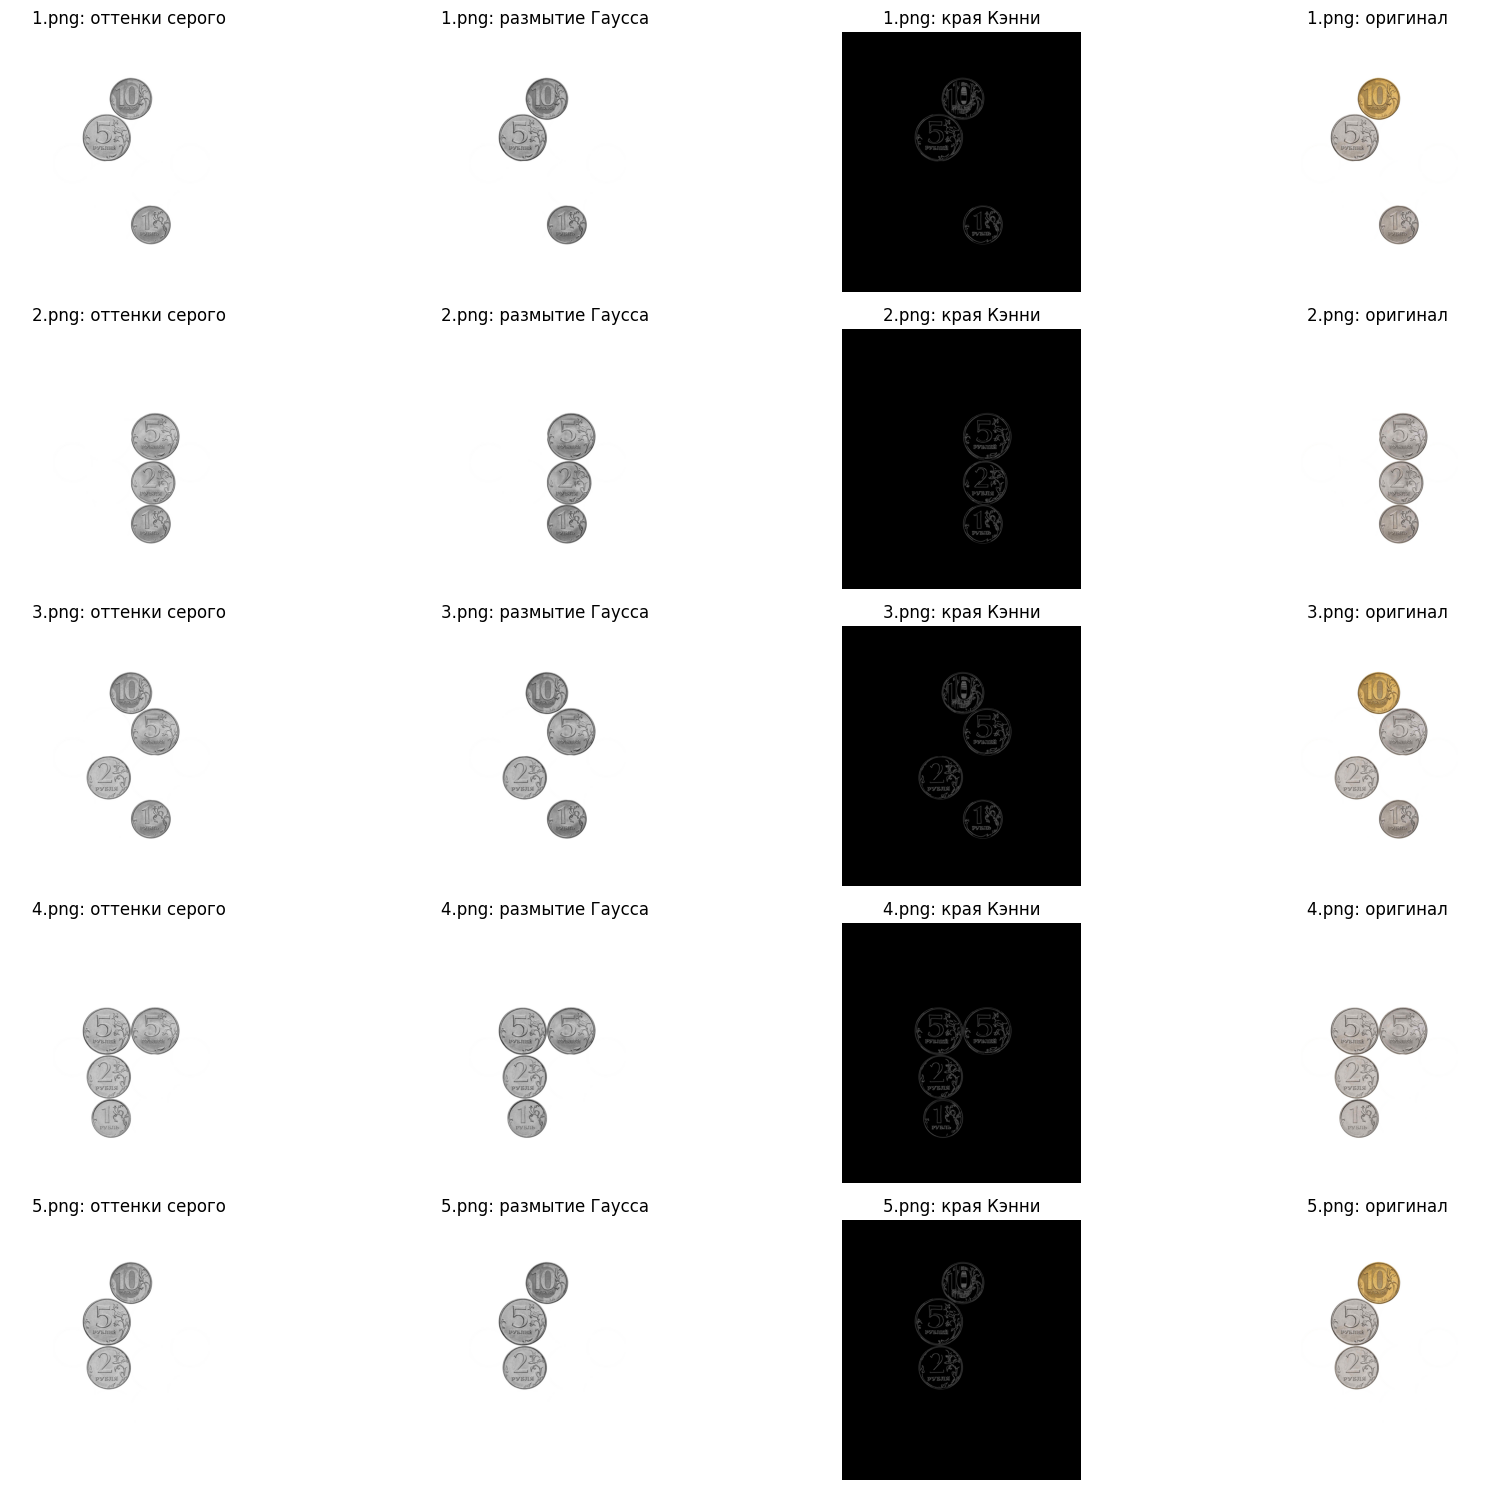



 Обработка картинки: 1.png

  Монетка 1: радиус=264, вертикальных=171, горизонтальных=268, номинал=5 руб.
  Монетка 2: радиус=225, вертикальных=265, горизонтальных=119, номинал=1 руб.
  Монетка 3: радиус=227, вертикальных=909, горизонтальных=39, номинал=10 руб.

  Найдено монеток: 3
  Номиналы: 5, 1, 10
  Общая сумма: 16 рублей



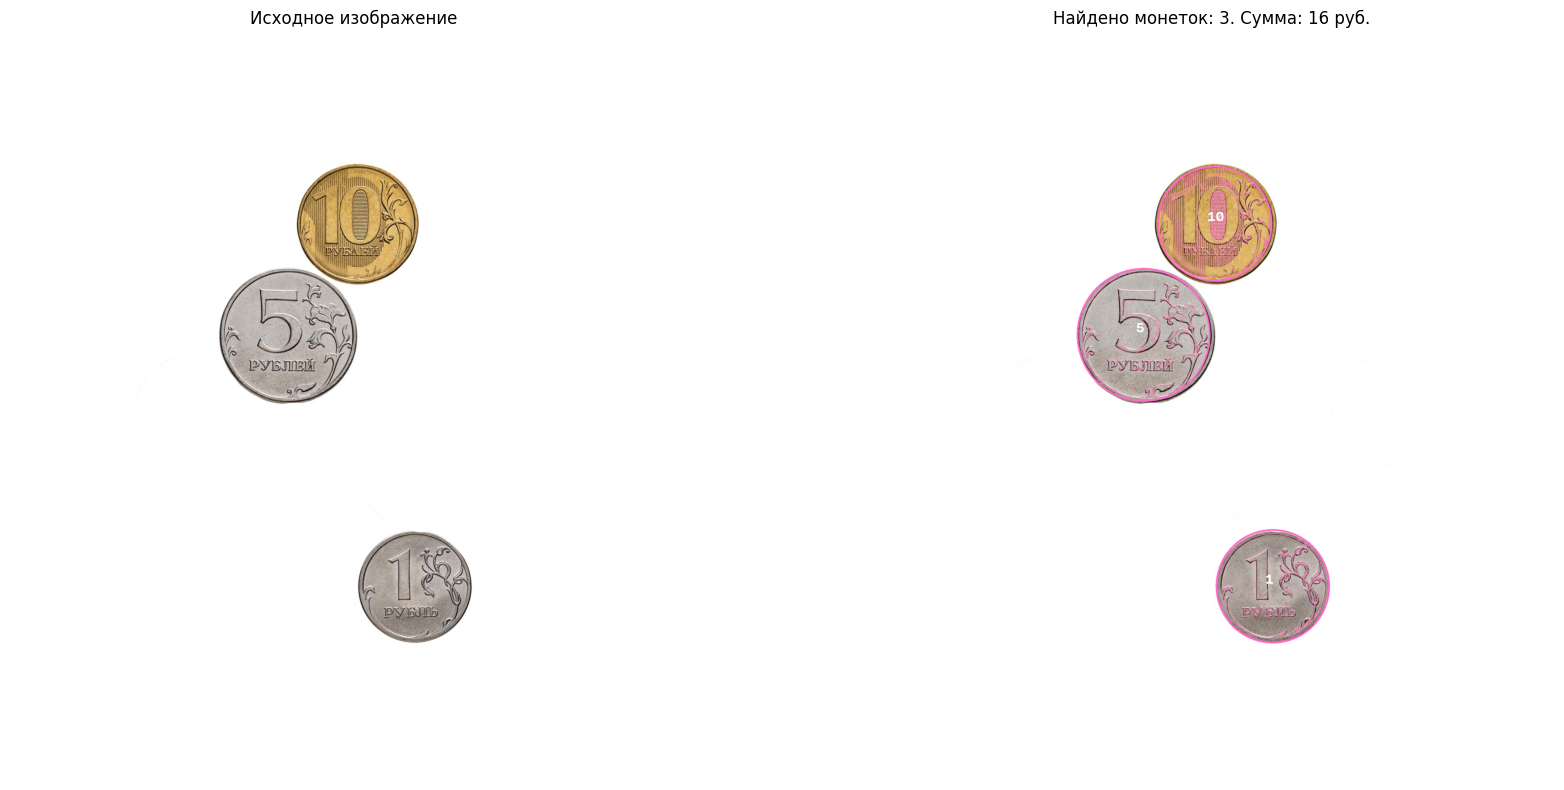



 Обработка картинки: 2.png

  Монетка 1: радиус=251, вертикальных=273, горизонтальных=224, номинал=2 руб.
  Монетка 2: радиус=254, вертикальных=176, горизонтальных=244, номинал=5 руб.
  Монетка 3: радиус=226, вертикальных=285, горизонтальных=147, номинал=1 руб.

  Найдено монеток: 3
  Номиналы: 2, 5, 1
  Общая сумма: 8 рублей



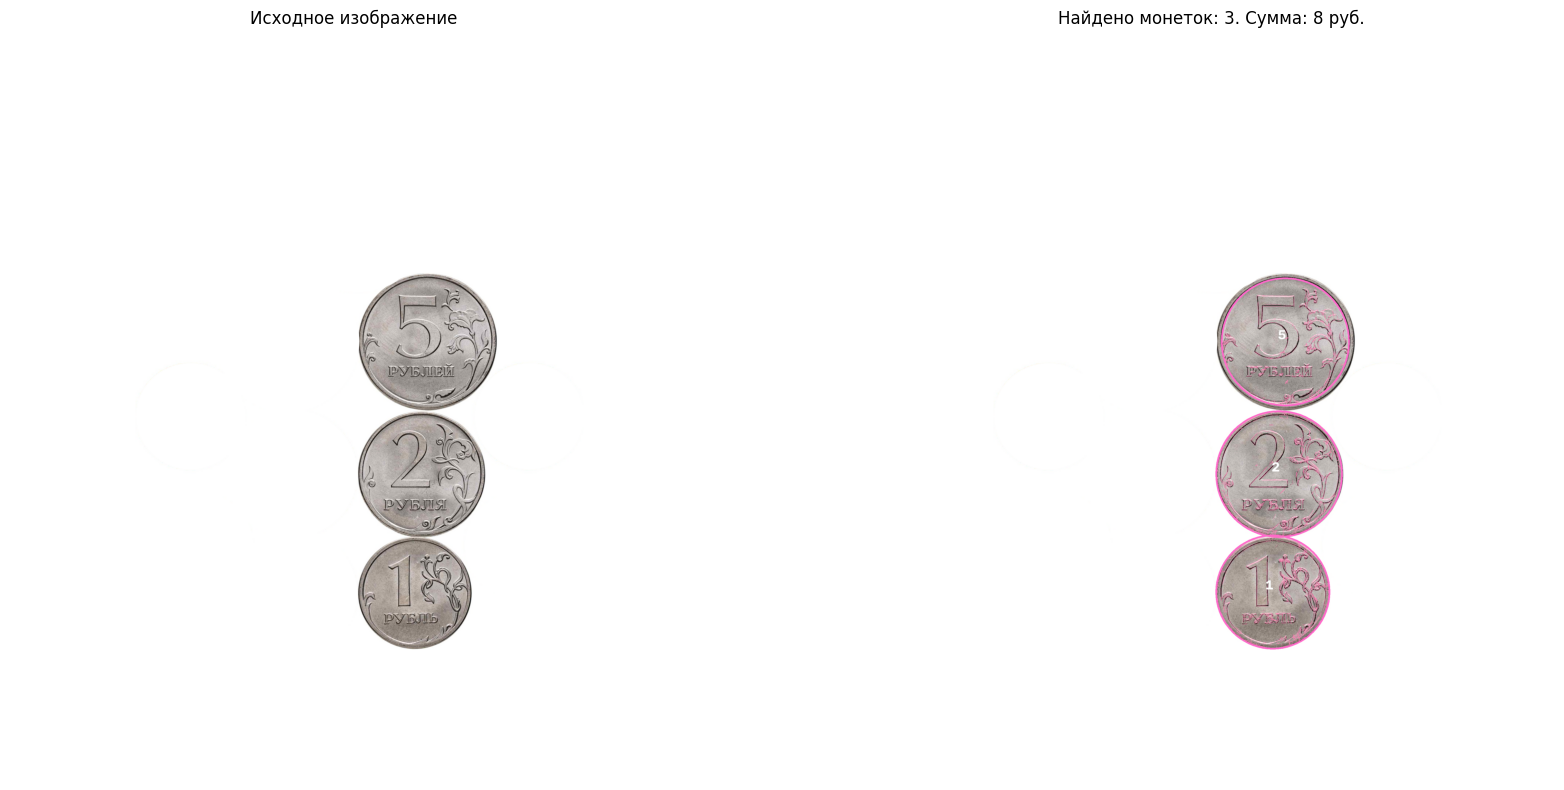



 Обработка картинки: 3.png

  Монетка 1: радиус=246, вертикальных=238, горизонтальных=231, номинал=2 руб.
  Монетка 2: радиус=257, вертикальных=198, горизонтальных=238, номинал=5 руб.
  Монетка 3: радиус=224, вертикальных=267, горизонтальных=121, номинал=1 руб.
  Монетка 4: радиус=229, вертикальных=977, горизонтальных=31, номинал=10 руб.

  Найдено монеток: 4
  Номиналы: 2, 5, 1, 10
  Общая сумма: 18 рублей



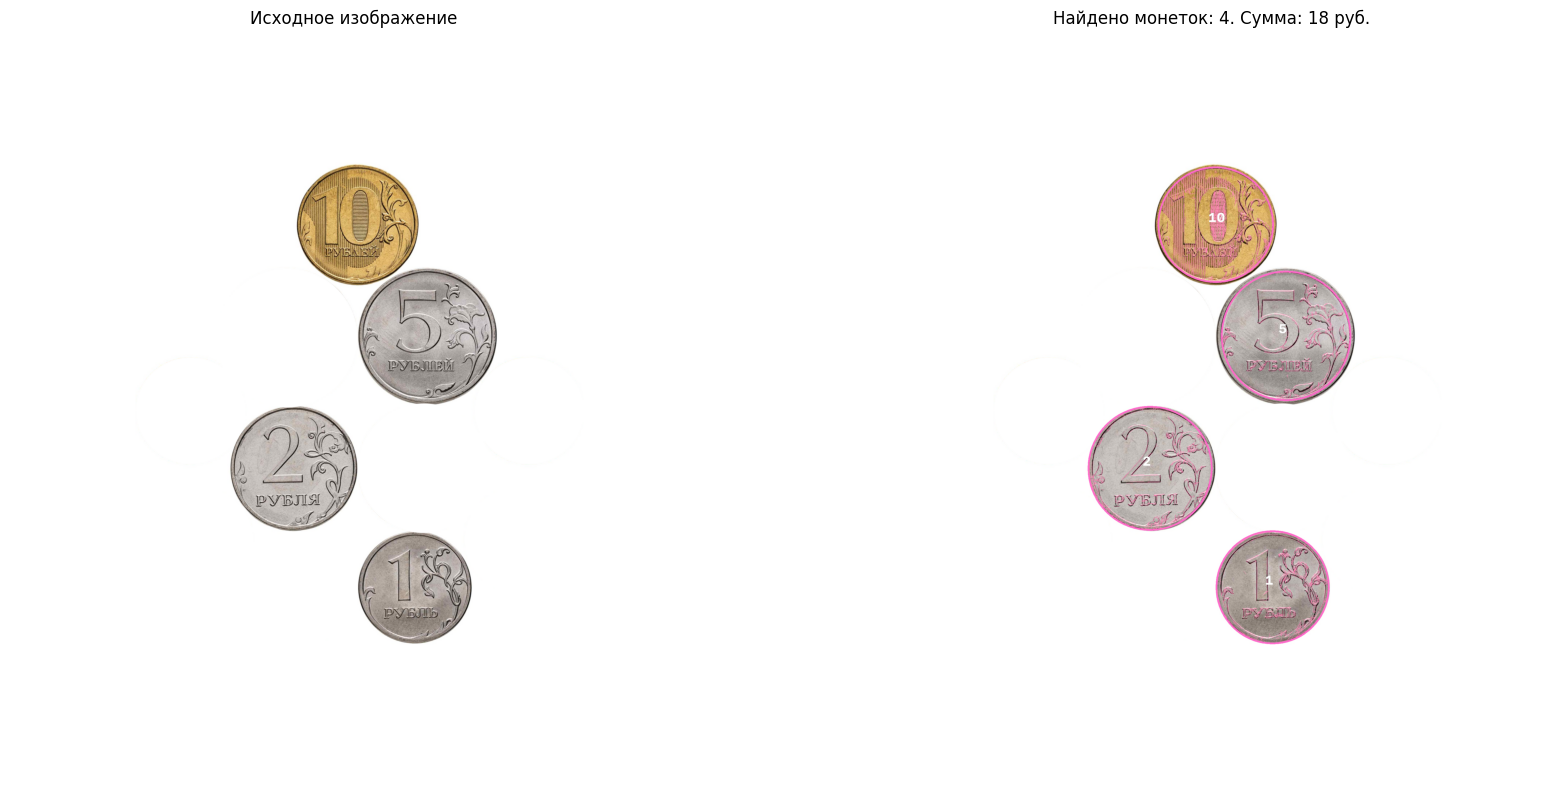



 Обработка картинки: 4.png

  Монетка 1: радиус=261, вертикальных=186, горизонтальных=252, номинал=5 руб.
  Монетка 2: радиус=254, вертикальных=179, горизонтальных=234, номинал=5 руб.
  Монетка 3: радиус=251, вертикальных=291, горизонтальных=219, номинал=2 руб.
  Монетка 4: радиус=224, вертикальных=285, горизонтальных=145, номинал=1 руб.

  Найдено монеток: 4
  Номиналы: 5, 5, 2, 1
  Общая сумма: 13 рублей



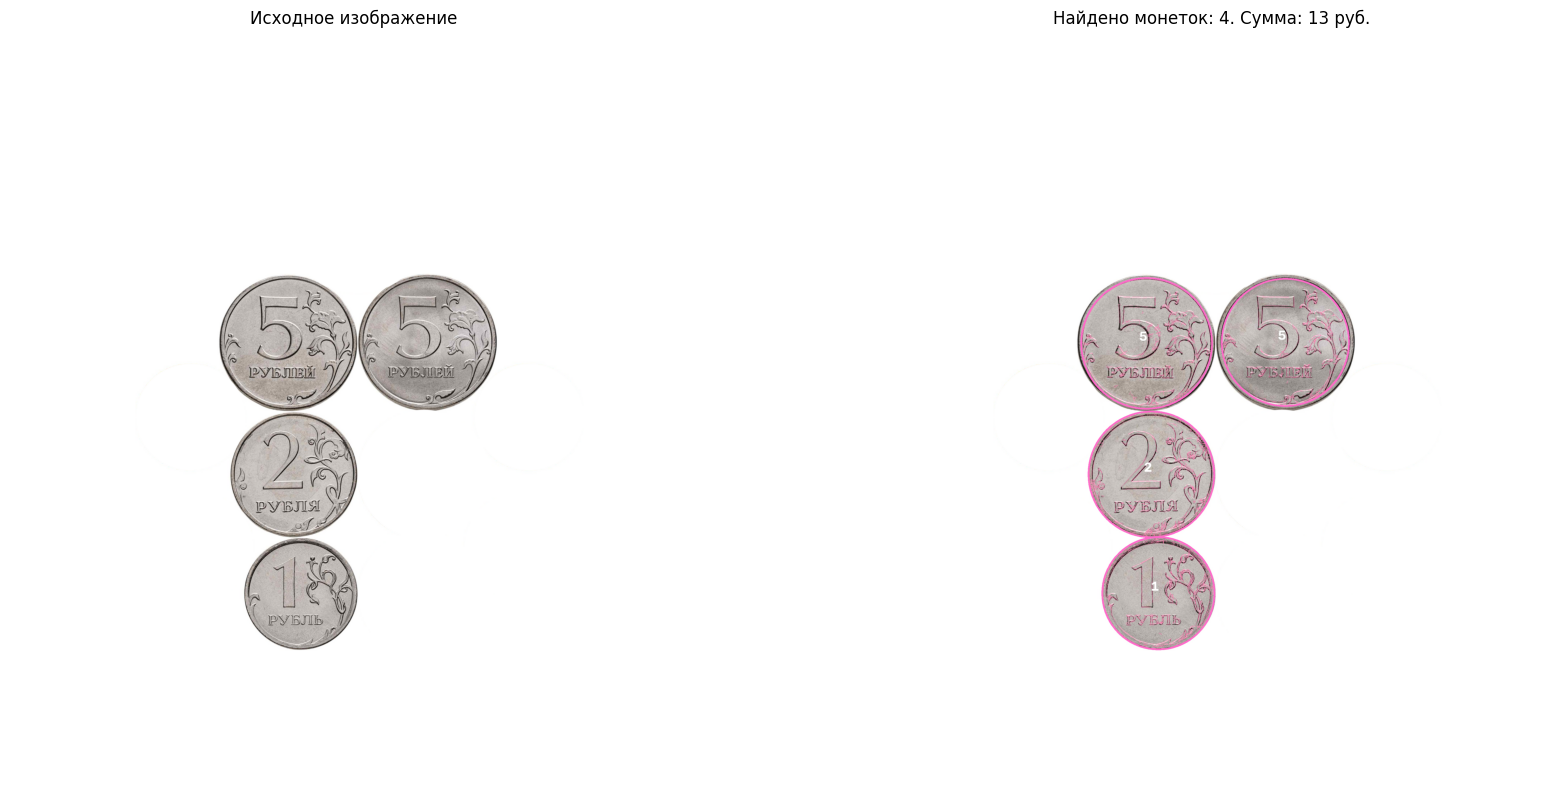



 Обработка картинки: 5.png

  Монетка 1: радиус=257, вертикальных=164, горизонтальных=226, номинал=5 руб.
  Монетка 2: радиус=230, вертикальных=911, горизонтальных=42, номинал=10 руб.
  Монетка 3: радиус=246, вертикальных=232, горизонтальных=226, номинал=2 руб.

  Найдено монеток: 3
  Номиналы: 5, 10, 2
  Общая сумма: 17 рублей



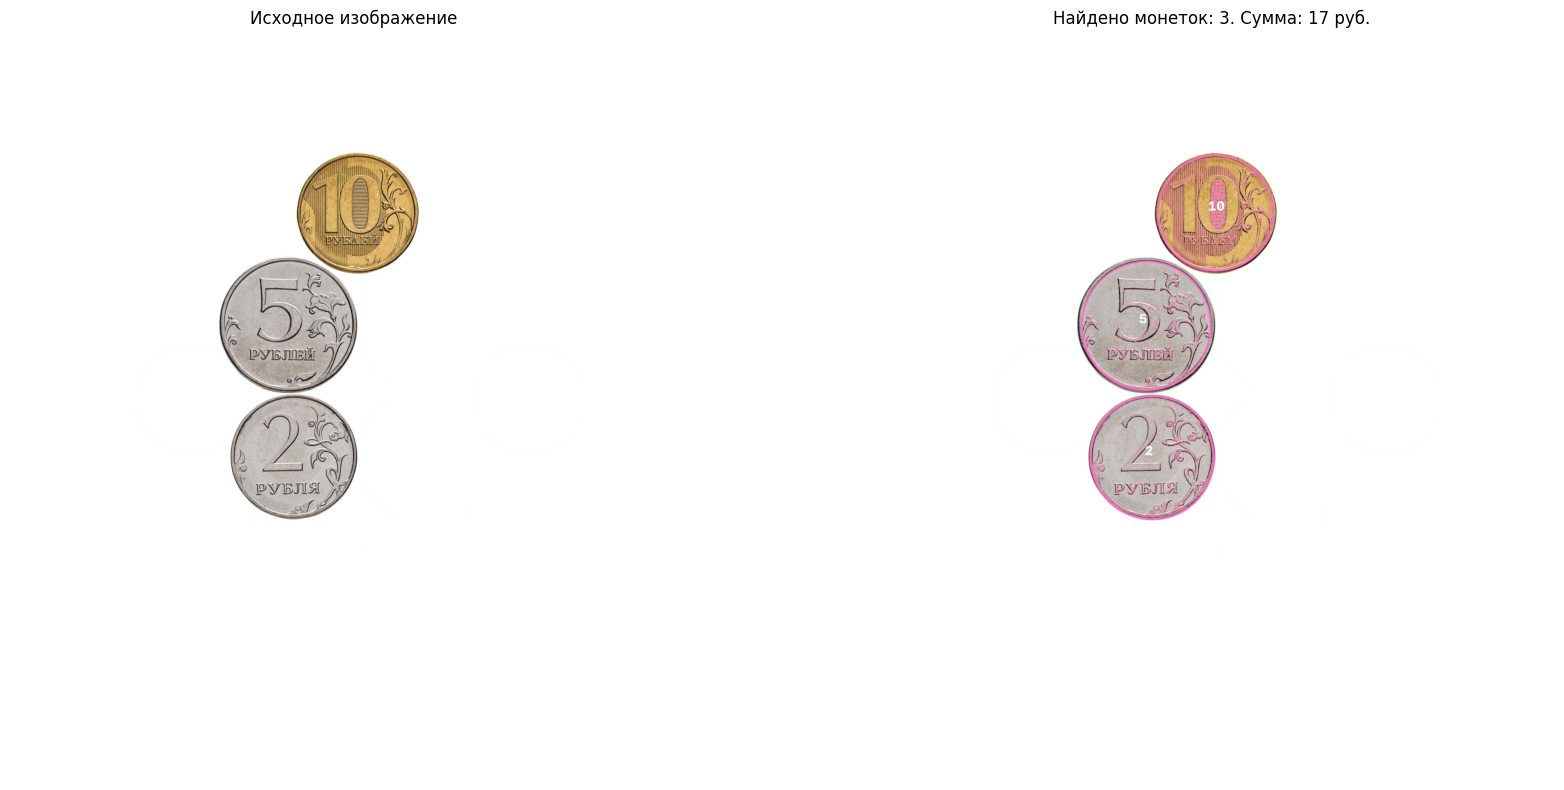



 Результатики

  Всего обработано картинок: 5
  Всего обнаружено монеток: 17
  Общая сумма по всем картинкам: 72 рублей (Дай бог на маленькую пачку чипсов хватит)



In [35]:
meow_title('Считаем монетки, ждите <3')

pictures = ['1.png', '2.png', '3.png', '4.png', '5.png']
fig, axes = plt.subplots(nrows=len(pictures), ncols=3, figsize=(18, 3 * len(pictures)))

for i, name in enumerate(pictures):
    img = cv2.imread(name)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (9, 9), 0)
    edges = cv2.Canny(blurred, 50, 150, apertureSize=3)
    axes[i, 0].imshow(gray, cmap='gray')
    axes[i, 0].set_title(f'{name}: оттенки серого')
    axes[i, 0].axis('off')
    axes[i, 1].imshow(blurred, cmap='gray')
    axes[i, 1].set_title(f'{name}: размытие Гаусса')
    axes[i, 1].axis('off')
    axes[i, 2].imshow(edges, cmap='gray')
    axes[i, 2].set_title(f'{name}: края Кэнни')
    axes[i, 2].axis('off')

plt.tight_layout()
plt.show()
print()



def find_coins(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (9, 9), 0)
    circles = cv2.HoughCircles(blurred, cv2.HOUGH_GRADIENT, dp=1.2, minDist=120, param1=200, param2=240, minRadius=30, maxRadius=290)
    return np.round(circles[0, :]).astype(np.int32)


def grab_inner_lines(image, cx, cy, r, canny_low=50, canny_high=150, hough_thresh=20, min_line_len=10, max_line_gap=5):
    h, w = image.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, (cx, cy), r, 255, -1)
    x1, y1 = max(cx - r, 0), max(cy - r, 0)
    x2, y2 = min(cx + r, w), min(cy + r, h)
    roi = image[y1:y2, x1:x2]
    roi_mask = mask[y1:y2, x1:x2]
    roi_gray = cv2.cvtColor(roi, cv2.COLOR_BGR2GRAY) if roi.ndim == 3 else roi
    roi_blur = cv2.GaussianBlur(roi_gray, (3, 3), 0)
    roi_edges = cv2.Canny(roi_blur, canny_low, canny_high)
    roi_edges = cv2.bitwise_and(roi_edges, roi_edges, mask=roi_mask)
    lines = cv2.HoughLinesP(roi_edges, rho=1, theta=np.pi / 180, threshold=hough_thresh, minLineLength=min_line_len, maxLineGap=max_line_gap)
    result_lines = []
    if lines is not None:
        for lx1, ly1, lx2, ly2 in lines.reshape(-1, 4):
            result_lines.append([int(lx1) + x1, int(ly1) + y1, int(lx2) + x1, int(ly2) + y1])
    return result_lines


def split_by_direction(lines):
    vertical_count = 0
    horizontal_count = 0
    for (x1, y1, x2, y2) in lines:
        dx, dy = x2 - x1, y2 - y1
        angle = np.degrees(np.arctan2(dy, dx)) % 180
        if angle < 20 or angle > 160:
            horizontal_count += 1
        elif 70 < angle < 110:
            vertical_count += 1
    return vertical_count, horizontal_count


coins = [(1, 225, 265, 119), (2, 253, 260, 226), (5, 257, 164, 230), (10, 228, 911, 42)]

tolerance = {'radius': 6, 'vertical': 40, 'horizontal': 40}


def closest_match(value, refs, tol):
    in_range = [(nom, abs(value - ref)) for nom, ref in refs if abs(value - ref) <= tol]
    if in_range:
        return min(in_range, key=lambda x: (x[1], x[0]))[0]
    return min(refs, key=lambda kv: abs(value - kv[1]))[0]



def name_the_coin(radius, vertical_count, horizontal_count):
    table = coins
    radius_matches = [(n, r) for n, r, v, h in table if abs(radius - r) <= tolerance['radius']]
    if len(radius_matches) == 1:
        return radius_matches[0][0]

    vertical_matches = [(n, v) for n, r, v, h in table if abs(vertical_count - v) <= tolerance['vertical']]
    if len(vertical_matches) == 1:
        return vertical_matches[0][0]

    horizontal_matches = [(n, h) for n, r, v, h in table if abs(horizontal_count - h) <= tolerance['horizontal']]
    if len(horizontal_matches) == 1:
        return horizontal_matches[0][0]

    return closest_match(radius, [(n, r) for n, r, v, h in table], tolerance['radius'])


grand_total = 0
grand_count = 0

for name in pictures:
    meow_title(f'Обработка картинки: {name}')
    img = cv2.imread(name)
    try:
        circles = find_coins(img)
    except (TypeError, IndexError):
        print(f'На картинке {name} монеток не обнаружено')
        print()
        continue

    result = img.copy()
    coin_values = []
    coin_info = []
    for i, (cx, cy, r) in enumerate(circles):
        lines = grab_inner_lines(img, cx, cy, r)
        v, h = split_by_direction(lines)
        nominal = name_the_coin(r, v, h)
        coin_values.append(nominal)
        coin_info.append((cx, cy, r, nominal))
        cv2.circle(result, (cx, cy), r, (203, 105, 255), 6)
        for (x1, y1, x2, y2) in lines:
            cv2.line(result, (x1, y1), (x2, y2), (180, 130, 255), 1)
        print(f'Монетка {i + 1}: радиус = {r}, вертикальных = {v}, горизонтальных = {h}, номинал = {nominal} руб.')
    total = sum(coin_values)
    for (cx, cy, r, nominal) in coin_info:
        cv2.putText(result, str(nominal), (cx - 30, cy - 10), cv2.FONT_HERSHEY_SIMPLEX, 1.8, (0, 0, 0), 8)
        cv2.putText(result, str(nominal), (cx - 30, cy - 10), cv2.FONT_HERSHEY_SIMPLEX, 1.8, (255, 255, 255), 4)

    print(f'\n  Найдено монеток: {len(coin_values)}\n  Номиналы: {", ".join(str(v) for v in coin_values)}\n  Общая сумма: {total} рублей\n')

    grand_total += total
    grand_count += len(coin_values)
    plt.figure(figsize=(18, 8))
    plt.subplot(1, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title('Исходное изображение')
    plt.axis('off')
    plt.subplot(1, 2, 2)
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f'Найдено монеток: {len(coin_values)}. Сумма: {total} руб.')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    print()


meow_title('Итог')
print(f'  Всего обработано картинок: {len(pictures)}\n  Всего обнаружено монеток: {grand_count}\n  Общая сумма по всем картинкам: {grand_total} рублей (Дай бог на маленькую пачку чипсов хватит)\n')